# 1.2 Data Integration and Cleaning

## A — Data Issues and Initial Cleaning

### Loading the Data
We preserve the original data and perform cleaning on working copies.
The files use different separators: a tab, a comma, and a semicolon.

In [221]:
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("../data")
if not DATA.is_dir():
    DATA = Path("data")

readings_raw = pd.read_csv(DATA / "readings.csv", sep="\t")
units_raw = pd.read_csv(DATA / "units.csv", sep=",")
gateways_raw = pd.read_csv(DATA / "gateways.csv", sep=";")

readings = readings_raw.copy()
units = units_raw.copy()
gateways = gateways_raw.copy()

for name, df in [
    ("readings", readings),
    ("units", units),
    ("gateways", gateways),
]:
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

readings: 13288 rows, 11 columns
units: 2000 rows, 9 columns
gateways: 16000 rows, 10 columns


### Checking Exact Duplicates
Exact duplicates have identical values in every column.
Matching device identifiers and dates alone do not prove that records
are duplicates. We inspect repeated records before removing them.

In [222]:
for name, df in [
    ("readings", readings),
    ("units", units),
    ("gateways", gateways),
]:
    print(f"{name}: {df.duplicated().sum()} extra duplicate rows")

display(
    readings.loc[readings.duplicated(keep=False)]
    .sort_values(["unitId", "ts_cycle"])
    .head(20)
)

readings: 196 extra duplicate rows
units: 0 extra duplicate rows
gateways: 0 extra duplicate rows


,unitId,ts_cycle,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint,Failure
12504,U00001,2023/02/27,6.47386,14.19043,44.05953,8.01864,5.32535,24.97808,72.22405,9.09212,0
13138,U00001,2023/02/27,6.47386,14.19043,44.05953,8.01864,5.32535,24.97808,72.22405,9.09212,0
8837,U00013,2023-10-06,5.13802,13.60035,36.16077,9.32805,2.59613,29.41965,65.08389,5.12061,0
13280,U00013,2023-10-06,5.13802,13.60035,36.16077,9.32805,2.59613,29.41965,65.08389,5.12061,0
3095,U00019,01 Sep 2023,6.60985,14.87267,64.95792,8.65423,2.52225,29.62823,72.63180,15.77390,1
13105,U00019,01 Sep 2023,6.60985,14.87267,64.95792,8.65423,2.52225,29.62823,72.63180,15.77390,1
9438,U00029,2023/12/20,6.90859,26.38209,46.74425,7.80743,5.20277,27.89719,64.32724,5.40653,1
13124,U00029,2023/12/20,6.90859,26.38209,46.74425,7.80743,5.20277,27.89719,64.32724,5.40653,1
135,U00037,03 Dec 2023,7.52436,18.43928,55.47770,8.62802,1.99813,29.25452,67.60258,9.92346,0
13180,U00037,03 Dec 2023,7.52436,18.43928,55.47770,8.62802,1.99813,29.25452,67.60258,9.92346,0


### Removing Exact Duplicates

We treat rows identical in all columns as repeated records.
We keep the first occurrence and compare class counts before and after removal.

In [223]:
#remove exact copies while preserving the original table
readings = readings_raw.drop_duplicates().copy()

#check the effect on target classes
comparison = pd.DataFrame({
    "before": readings_raw["Failure"].value_counts(),
    "after": readings["Failure"].value_counts(),
}).sort_index()

comparison["removed"] = comparison["before"] - comparison["after"]
display(comparison)

print(f"Removed rows: {len(readings_raw) - len(readings)}")
print(f"Remaining rows: {len(readings)}")
print(f"Remaining exact duplicates: {readings.duplicated().sum()}")

,before,after,removed
Failure,,,
0,11663,11498,165
1,1625,1594,31


Removed rows: 196
Remaining rows: 13092
Remaining exact duplicates: 0


### Standardizing Device Keys

We use the numeric part of U-prefixed identifiers as a common device key.
This mapping is an assumption based on identifier structure.
Original identifiers are preserved; unmatched records are flagged.

In [224]:
#validate identifiers before conversion
ids = readings["unitId"].astype("string").str.strip()
invalid = ~ids.str.fullmatch(r"U[0-9]+", na=False)

if invalid.any():
    display(readings.loc[invalid, ["unitId"]])
    raise ValueError("Missing or unexpected identifiers in readings.")

#create common keys without replacing original identifiers
readings["unit_key"] = pd.to_numeric(ids.str[1:]).astype("Int64")

for df in (units, gateways):
    df["unit_key"] = pd.to_numeric(
        df["unitId"], errors="raise"
    ).astype("Int64")

#check that normalization does not collapse distinct identifiers
key_mapping = readings[["unitId", "unit_key"]].drop_duplicates()
assert key_mapping["unit_key"].is_unique, (
    "Different original identifiers map to the same key."
)

#require a unique device lookup before any join
assert units["unit_key"].notna().all(), "Missing device keys in units."
assert units["unit_key"].is_unique, "Duplicate device keys in units."

#flag unmatched readings instead of deleting them
readings["unit_metadata_missing"] = ~readings["unit_key"].isin(
    units["unit_key"]
)

#inspect gateway links separately from missing identifiers
linked_gateways = gateways.loc[gateways["unit_key"].notna()]

display(pd.Series({
    "unmatched_readings": readings["unit_metadata_missing"].sum(),
    "gateways_without_device_key": gateways["unit_key"].isna().sum(),
    "extra_gateway_links_per_device": (
        linked_gateways["unit_key"].duplicated().sum()
    ),
    "unmatched_gateway_links": (
        ~linked_gateways["unit_key"].isin(units["unit_key"])
    ).sum(),
}).to_frame("count"))

#check whether missing device metadata affects one class more often
display(
    readings.groupby("Failure")["unit_metadata_missing"]
    .agg(rows="size", unmatched="sum", unmatched_rate="mean")
    .assign(unmatched_percent=lambda df: df["unmatched_rate"] * 100)
    .drop(columns="unmatched_rate")
    .round(2)
)

,count
unmatched_readings,131
gateways_without_device_key,14000
extra_gateway_links_per_device,0
unmatched_gateway_links,0


,rows,unmatched,unmatched_percent
Failure,,,
0,11498,117,1.02
1,1594,14,0.88


### Standardizing Dates

Original date columns are preserved.
We parse explicit formats and flag ambiguous numeric dates.
Date-only records are distinguished from records containing a time.

In [225]:
def standardize_dates(series):
    text = series.astype("string").str.strip()
    parsed = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")

    #parse year-first dates and dates with named months
    for fmt in ("%Y-%m-%d", "%Y/%m/%d", "%d %b %Y"):
        candidate = pd.to_datetime(text, format=fmt, errors="coerce")
        parsed = parsed.fillna(candidate)

    #compare both interpretations of numeric dates
    month_first = pd.to_datetime(
        text, format="%m/%d/%Y, %H:%M:%S", errors="coerce"
    )
    day_first = pd.to_datetime(
        text, format="%d/%m/%Y, %H:%M:%S", errors="coerce"
    )

    ambiguous = (
        month_first.notna()
        & day_first.notna()
        & month_first.ne(day_first)
    )

    numeric = month_first.fillna(day_first).mask(ambiguous)
    parsed = parsed.fillna(numeric)

    #distinguish unresolved dates from original missing values
    status = pd.Series("unparsed", index=series.index, dtype="string")
    status.loc[text.isna() | text.eq("")] = "missing"
    status.loc[parsed.notna()] = "parsed"
    status.loc[ambiguous] = "ambiguous"

    return pd.DataFrame({
        "parsed": parsed,
        "status": status,
        "has_time": text.str.contains(
            r"\d{2}:\d{2}:\d{2}", regex=True, na=False
        ),
    })


for name, df, column in [
    ("readings", readings, "ts_cycle"),
    ("gateways", gateways, "seenLast"),
]:
    result = standardize_dates(df[column])

    #preserve source values and add parsed values and quality flags
    for suffix in result.columns:
        df[f"{column}_{suffix}"] = result[suffix]

    print(f"\n{name}: {column}")
    display(result["status"].value_counts().to_frame("rows"))

    #show examples requiring review
    unresolved = result["status"].isin(["ambiguous", "unparsed"])
    display(
        df.loc[unresolved, [column, f"{column}_status"]].head(5)
    )


readings: ts_cycle


,rows
status,
parsed,11958
ambiguous,1134


,ts_cycle,ts_cycle_status
4,"05/06/2023, 02:23:00",ambiguous
16,"06/02/2023, 17:32:00",ambiguous
22,"12/03/2023, 10:28:00",ambiguous
30,"04/07/2023, 18:40:00",ambiguous
32,"12/07/2023, 01:07:00",ambiguous



gateways: seenLast


,rows
status,
parsed,14605
ambiguous,1395


,seenLast,seenLast_status
2,"08/10/2024, 00:00:00",ambiguous
4,"06/01/2024, 00:00:00",ambiguous
7,"04/09/2024, 00:00:00",ambiguous
14,"09/06/2024, 00:00:00",ambiguous
19,"05/08/2024, 00:00:00",ambiguous


### Cleaning Category Whitespace

We remove surrounding whitespace from class_duty.
Original values are preserved. Category codes are not merged without
a confirmed mapping.

In [226]:
#remove surrounding spaces while preserving original categories
original = units["class_duty"].astype("string")
units["class_duty_clean"] = original.str.strip()

changed = original.ne(units["class_duty_clean"]).fillna(False)

print(f"Rows changed: {changed.sum()}")
print(f"Unique categories before: {original.nunique()}")
print(f"Unique categories after: {units['class_duty_clean'].nunique()}")

#make spaces visible in the comparison
display(
    pd.DataFrame({
        "original": original.map(repr),
        "cleaned": units["class_duty_clean"].map(repr),
    })
    .value_counts()
    .rename("rows")
    .reset_index()
)

Rows changed: 202
Unique categories before: 20
Unique categories after: 10


,original,cleaned,rows
0,'1','1',277
1,'L','L',239
2,'light','light',226
3,'med','med',189
4,'H','H',165
5,'N','N',153
6,'3','3',141
7,'2','2',138
8,'heavy','heavy',136
9,'normal','normal',134


### Missing Values

We inspect missing values in source columns and compare sensor
missingness between Failure classes. Missing measurements are retained;
imputation will be fitted on training data in Phase 2.

In [227]:
#report missing values in source columns only
reports = []

for name, df, source in [
    ("readings", readings, readings_raw),
    ("units", units, units_raw),
    ("gateways", gateways, gateways_raw),
]:
    missing = df[source.columns].isna()

    reports.append(pd.DataFrame({
        "table": name,
        "column": source.columns,
        "missing_count": missing.sum().to_numpy(),
        "missing_percent": (missing.mean() * 100).to_numpy(),
    }))

missing_summary = pd.concat(reports, ignore_index=True)

display(
    missing_summary.loc[missing_summary["missing_count"] > 0]
    .round(2)
    .reset_index(drop=True)
)

#compare sensor missingness between classes
sensors = [
    "motorCurrent", "filterDp", "temperatureOil",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]

display(
    readings[sensors].isna()
    .groupby(readings["Failure"])
    .mean()
    .mul(100)
    .T
    .round(2)
)

#preserve missingness information as explicit flags
for column in ["filterDp", "vibrationRms"]:
    readings[f"{column}_missing"] = readings[column].isna()

units["serviceHours_missing"] = units["serviceHours"].isna()

,table,column,missing_count,missing_percent
0,readings,filterDp,531,4.06
1,readings,vibrationRms,511,3.90
2,units,serviceHours,100,5.00
3,gateways,unitId,14000,87.50


Failure,0,1
motorCurrent,0.00,0.00
filterDp,2.05,18.51
temperatureOil,0.00,0.00
pressure_reservoir,0.00,0.00
vibrationRms,1.86,18.63
flowmeter,0.00,0.00
tempBearing,0.00,0.00
discharge_dewpoint,0.00,0.00


### Handling Invalid Oil Temperature

We treat temperatureOil = -999 as an invalid measurement.
Its exact meaning is undocumented. Original values are preserved;
a cleaned column replaces -999 with missing values.

In [228]:
#check the suspected invalid value against the remaining measurements
invalid = readings["temperatureOil"].eq(-999)
other_values = readings.loc[~invalid, "temperatureOil"]

print(f"Values equal to -999: {invalid.sum()}")
print(f"Other values: {other_values.min()} to {other_values.max()}")

#preserve the original column and flag invalid measurements
readings["temperatureOil_invalid"] = invalid
readings["temperatureOil_clean"] = readings["temperatureOil"].mask(invalid)

print(
    "Missing cleaned temperatures:",
    readings["temperatureOil_clean"].isna().sum(),
)

#check how often invalid temperatures occur in each class
display(
    readings.groupby("Failure")["temperatureOil_invalid"]
    .agg(count="sum", percent=lambda values: values.mean() * 100)
    .round(2)
)

Values equal to -999: 41
Other values: 15.0 to 95.0
Missing cleaned temperatures: 41


,count,percent
Failure,,
0,33,0.29
1,8,0.50


### Integrating Device Metadata

We join readings with units using unit_key.
A left join preserves unmatched readings.
The many-to-one constraint prevents duplicate device keys from
multiplying measurements.

Metadata availability at the measurement time remains to be verified
before predictive modelling.

In [229]:
#preserve source row identifiers for checking the join
assert readings.index.is_unique, "Reading row identifiers are not unique."
assert units["unit_key"].notna().all(), "Missing device keys."

source = readings.assign(reading_row_id=readings.index)

#avoid adding a second copy of the original unitId column
device_metadata = units.drop(columns="unitId")

#attach device metadata while retaining all readings
integrated = source.merge(
    device_metadata,
    on="unit_key",
    how="left",
    validate="many_to_one",
    indicator="device_match",
    sort=False,
)

#verify that observations and target labels were preserved
assert len(integrated) == len(readings), "The join changed the row count."
assert integrated["reading_row_id"].is_unique, "The join duplicated readings."

pd.testing.assert_series_equal(
    integrated.set_index("reading_row_id")["Failure"].sort_index(),
    source.set_index("reading_row_id")["Failure"].sort_index(),
)

#сompare flag values using the same boolean type
pd.testing.assert_series_equal(
    integrated["device_match"].eq("left_only").astype("boolean"),
    integrated["unit_metadata_missing"].astype("boolean"),
    check_names=False,
)

print(f"Rows before: {len(readings)}")
print(f"Rows after: {len(integrated)}")
display(integrated["device_match"].value_counts().to_frame("rows"))

display(
    integrated[[
        "unitId", "unit_key", "Failure",
        "commission_year", "serviceHours", "device_match",
    ]].head()
)

Rows before: 13092
Rows after: 13092


,rows
device_match,
both,12961
left_only,131
right_only,0


,unitId,unit_key,Failure,commission_year,serviceHours,device_match
0,U00596,596,0,2021.0,11693.5,both
1,U00540,540,0,2019.0,18726.1,both
2,U00927,927,0,2020.0,14315.5,both
3,U01299,1299,0,2017.0,NaN,both
4,U01092,1092,0,2023.0,4149.4,both


The join preserved all 13,092 readings and their Failure labels.
Device metadata matched 12,961 readings; 131 remained unmatched.
No readings were duplicated by the join.

## B — Data Consistency Checks

We check target labels, non-finite measurements, negative service hours
and readings dated before the commissioning year.

Temporal checks use only resolved dates and available device metadata.
Flagged records are retained for review.

In [230]:
#use the cleaned temperature in numeric checks
sensor_columns = [
    "motorCurrent", "filterDp", "temperatureOil_clean",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]

#distinguish missing measurements from infinite values
values = integrated[sensor_columns]

display(pd.DataFrame({
    "missing": values.isna().sum(),
    "infinite": (values.notna() & ~np.isfinite(values)).sum(),
}))

#flag invalid or missing target labels
integrated["invalid_target"] = ~integrated["Failure"].isin([0, 1])

#check service hours only where available
hours = integrated["serviceHours"]
integrated["negative_serviceHours"] = (
    hours.lt(0).where(hours.notna()).astype("boolean")
)

#check years only when the date and commissioning year are available
date = integrated["ts_cycle_parsed"]
year = integrated["commission_year"]
eligible = date.notna() & year.notna()

integrated["before_commissioning"] = (
    date.dt.year.lt(year).where(eligible).astype("boolean")
)

#report checked, flagged and unavailable cases separately
flags = integrated[[
    "invalid_target",
    "negative_serviceHours",
    "before_commissioning",
]]

display(pd.DataFrame({
    "checked": flags.notna().sum(),
    "flagged": flags.sum(),
    "not_checkable": flags.isna().sum(),
}))

#inspect examples of temporal inconsistencies
display(
    integrated.loc[
        integrated["before_commissioning"].fillna(False),
        ["unitId", "ts_cycle", "ts_cycle_parsed", "commission_year"],
    ].head(10)
)

,missing,infinite
motorCurrent,0,0
filterDp,531,0
temperatureOil_clean,41,0
pressure_reservoir,0,0
vibrationRms,511,0
flowmeter,0,0
tempBearing,0,0
discharge_dewpoint,0,0


,checked,flagged,not_checkable
invalid_target,13092,0,0
negative_serviceHours,12349,0,743
before_commissioning,11840,238,1252


,unitId,ts_cycle,ts_cycle_parsed,commission_year
9,U01913,2023-12-12,2023-12-12 00:00:00,2024.0
15,U00343,2023/07/29,2023-07-29 00:00:00,2024.0
43,U01354,2023/09/30,2023-09-30 00:00:00,2024.0
165,U01356,29 Jan 2023,2023-01-29 00:00:00,2024.0
259,U00343,2023/06/07,2023-06-07 00:00:00,2024.0
288,U00155,2023/01/13,2023-01-13 00:00:00,2024.0
305,U01516,"09/20/2023, 02:18:00",2023-09-20 02:18:00,2024.0
328,U00809,"10/16/2023, 04:17:00",2023-10-16 04:17:00,2024.0
395,U01381,2023/01/01,2023-01-01 00:00:00,2024.0
573,U00617,19 Sep 2023,2023-09-19 00:00:00,2024.0


### Temporal Findings

238 readings precede the recorded commissioning year.
We retain and flag these records because the incorrect field is unknown.
For 1,252 readings, the temporal check is unavailable.

### Device–Gateway Consistency

We compare depot identifiers for gateways linked to devices.
This checks agreement between the supplied metadata tables,
not historical gateway assignments.

In [231]:
#check only gateways with a device key
linked = gateways.loc[gateways["unit_key"].notna()]

#match gateway and device depots without multiplying records
depot_check = linked[["id_gateway", "unit_key", "id_depot"]].merge(
    units[["unit_key", "id_depot"]],
    on="unit_key",
    how="left",
    validate="one_to_one",
    suffixes=("_gateway", "_unit"),
    indicator=True,
)

#compare only matched records with both depot values available
eligible = (
    depot_check["_merge"].eq("both")
    & depot_check["id_depot_gateway"].notna()
    & depot_check["id_depot_unit"].notna()
)

mismatch = eligible & depot_check["id_depot_gateway"].ne(
    depot_check["id_depot_unit"]
)

display(pd.Series({
    "checked_links": eligible.sum(),
    "depot_mismatches": mismatch.sum(),
    "not_checkable": (~eligible).sum(),
}).to_frame("count"))

display(depot_check.loc[mismatch].head(10))



,count
checked_links,2000
depot_mismatches,0
not_checkable,0


,id_gateway,unit_key,id_depot_gateway,id_depot_unit,_merge


### Checking Conflicting Labels

We check whether identical device, timestamp and sensor records have
different Failure labels. Only resolved timestamps with explicit times
are checked. Conflicts are reported without automatic relabelling.

In [232]:
#use only resolved timestamps containing an explicit time
eligible = (
    integrated["unit_key"].notna()
    & integrated["ts_cycle_parsed"].notna()
    & integrated["ts_cycle_has_time"]
)

#compare original measurements, including original oil temperature
original_sensors = [
    "motorCurrent", "filterDp", "temperatureOil",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]
keys = ["unit_key", "ts_cycle_parsed"] + original_sensors

#keep missing sensor values as part of the record comparison
label_counts = (
    integrated.loc[eligible]
    .groupby(keys, dropna=False)["Failure"]
    .nunique()
)

conflicts = label_counts[label_counts > 1].reset_index(
    name="distinct_labels"
)

print(f"Checked readings: {eligible.sum()}")
print(f"Readings outside this check: {(~eligible).sum()}")
print(f"Conflicting record groups: {len(conflicts)}")

display(conflicts.head(10))

Checked readings: 2059
Readings outside this check: 11033
Conflicting record groups: 0


,unit_key,ts_cycle_parsed,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint,distinct_labels


No conflicting labels were found among 2,059 eligible readings.
The remaining 11,033 readings were outside this check.

## C — Outlier Treatment

We compare IQR-based row removal and clipping at the 5th and 95th
percentiles on separate copies. Missing values are preserved.
Statistical outliers are not automatically considered measurement errors.

Thresholds calculated here are exploratory. For modelling, they must
be fitted on training data only.

In [233]:
#use the cleaned temperature and exclude identifiers and target labels
outlier_columns = [
    "motorCurrent", "filterDp", "temperatureOil_clean",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]
baseline = integrated.copy()
values = baseline[outlier_columns]

#Method 1: flag values outside the 1.5 IQR boundaries
q1 = values.quantile(0.25)
q3 = values.quantile(0.75)
iqr = q3 - q1

lower_iqr = q1 - 1.5 * iqr
upper_iqr = q3 + 1.5 * iqr

outside_iqr = values.lt(lower_iqr) | values.gt(upper_iqr)
remove_row = outside_iqr.any(axis=1)

#remove rows containing at least one flagged sensor value
iqr_removed = baseline.loc[~remove_row].copy()

#Method 2: clip values without removing rows
lower_clip = values.quantile(0.05)
upper_clip = values.quantile(0.95)

clipped = baseline.copy()
clipped[outlier_columns] = values.clip(
    lower=lower_clip, upper=upper_clip, axis="columns"
)

#count actual changes; missing values do not count as changes
changed = values.notna() & values.ne(clipped[outlier_columns])

display(pd.DataFrame({
    "iqr_lower": lower_iqr,
    "iqr_upper": upper_iqr,
    "iqr_flagged_values": outside_iqr.sum(),
    "clip_lower": lower_clip,
    "clip_upper": upper_clip,
    "clipped_values": changed.sum(),
}).round(2))

,iqr_lower,iqr_upper,iqr_flagged_values,clip_lower,clip_upper,clipped_values
motorCurrent,-0.63,10.86,14,2.43,8.24,1310
filterDp,-2.60,47.91,513,11.65,45.90,1256
temperatureOil_clean,22.17,87.56,89,35.08,74.67,1306
pressure_reservoir,7.07,10.35,80,7.72,9.68,1310
vibrationRms,-0.86,6.57,472,1.18,6.14,1258
flowmeter,17.28,38.69,108,21.38,34.61,1310
tempBearing,43.34,86.69,86,51.71,78.25,1310
discharge_dewpoint,-1.61,17.58,75,2.24,13.78,1310


### Impact on Failure Classes

We compare retained rows, failure proportions and removal rates
within each class.

In [234]:
#compare dataset sizes and class proportions
variants = {
    "baseline": baseline,
    "iqr_removal": iqr_removed,
    "percentile_clipping": clipped,
}

display(pd.DataFrame([
    {
        "method": name,
        "rows": len(df),
        "removed_rows": len(baseline) - len(df),
        "failure_rows": df["Failure"].eq(1).sum(),
        "failure_percent": df["Failure"].eq(1).mean() * 100,
    }
    for name, df in variants.items()
]).round(2))

#measure removal rates separately within each class
removal_impact = (
    baseline.assign(removed_by_iqr=remove_row)
    .groupby("Failure")["removed_by_iqr"]
    .agg(total="size", removed="sum")
)
removal_impact["removed_percent"] = (
    100 * removal_impact["removed"] / removal_impact["total"]
)

display(removal_impact.round(2))

#verify that clipping preserved rows, labels and missing values
assert clipped.index.equals(baseline.index)
pd.testing.assert_series_equal(clipped["Failure"], baseline["Failure"])
assert clipped[outlier_columns].isna().equals(values.isna())

,method,rows,removed_rows,failure_rows,failure_percent
0,baseline,13092,0,1594,12.18
1,iqr_removal,11703,1389,1352,11.55
2,percentile_clipping,13092,0,1594,12.18


,total,removed,removed_percent
Failure,,,
0,11498,1147,9.98
1,1594,242,15.18


### Distribution Comparison

We compare filterDp and vibrationRms before and after both treatments.
Outlier markers are hidden; each panel uses one scale for all methods.

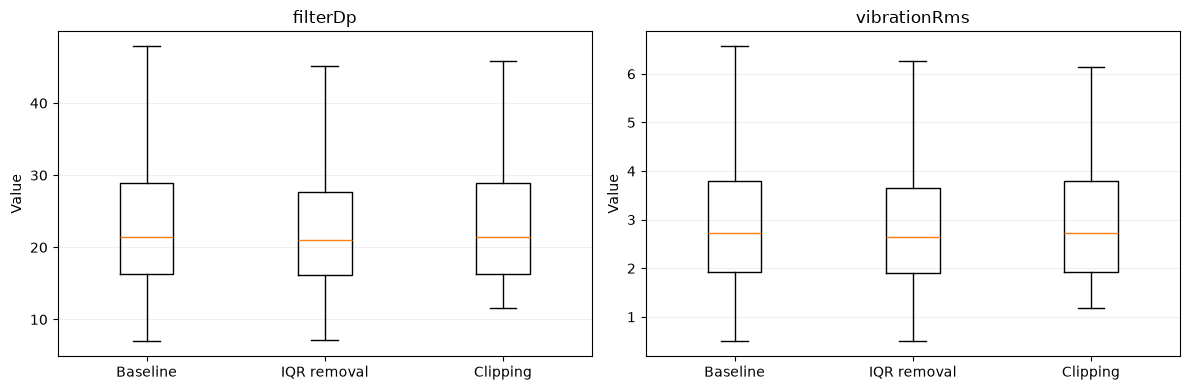

In [235]:
#compare the sensors with the most IQR-flagged values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column in zip(axes, ["filterDp", "vibrationRms"]):
    groups = [
        df[column].dropna()
        for df in (baseline, iqr_removed, clipped)
    ]

    ax.boxplot(groups, showfliers=False)
    ax.set_xticks([1, 2, 3], labels=["Baseline", "IQR removal", "Clipping"])
    ax.set_title(column)
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Findings and Decision

IQR removal excluded 1,389 readings, including 242 failure-labelled rows.
It removed 15.18% of failure rows versus 9.98% of non-failure rows.
The failure proportion decreased from 12.18% to 11.55%.

Clipping preserved all rows and labels but modified approximately 10%
of available values per sensor, potentially suppressing failure signals.

We retain baseline as the working dataset and keep both treatments
as experimental alternatives. Neither method is selected as universally
better without model validation.

## Summary and Remaining Limitations

- Removed 196 exact duplicate rows.
- Standardized device keys and category whitespace.
- Replaced 41 invalid oil temperatures in a separate cleaned column.
- Integrated device metadata without changing the 13,092 reading rows.
- Compared two outlier treatments; retained baseline for further analysis.

Unresolved issues:
- 1,134 reading dates and 1,395 gateway dates remain ambiguous.
- 131 readings lack device metadata.
- 238 readings precede the recorded commissioning year.
- Missing measurements remain unfilled.
- Gateway metadata is not included in the working dataset.